# TUGAS 2 — VISUALISASI DATA DERET WAKTU
**203012520032 - Seagata Ade Pratama Barus** <br>
***Visualisasi Data Lanjut (CAK7AGB4)***

## 0 - _Ouverture_

### Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
import warnings
import matplotlib.colors as mcolors
from scipy import stats
import statsmodels.formula.api as smf


warnings.filterwarnings("ignore")

### Theme

In [2]:
furina_bubble = {
    "abyss_black":     "#12161E",  # Added as the starting shade
    "ousia_navy":      "#152C5B",  # Blue 1
    "royal_blue":      "#2C50A5",  # Blue 2
    "slate_blue":      "#5883C4",  # Blue 3
    "pneuma_cyan":     "#3EA9E8",  # Blue 4
    "bubble_teal":     "#96fffe",  # Blue 5
    "ice_white":       "#FAFCFF",  # Blue 6 (Pale/White)
    "firefly_green":   "#7AE5AC",
    "deep_pink":       "#C73B6F",
    "elysian_pink":    "#FF6EB4",
    "herta_purple":    "#6B528D",
    "december_grey":   "#8A96A8",
    "bubblegum":       "#a5ece7",
    "soft_bg":         "#F4F7FB",
    "extra":           "#ffffff"
}

categorical_palette = [
    furina_bubble["pneuma_cyan"],
    furina_bubble["ousia_navy"],
    furina_bubble["elysian_pink"],
    furina_bubble["slate_blue"],
    furina_bubble["firefly_green"],
    furina_bubble["bubblegum"],
    furina_bubble["herta_purple"],
    furina_bubble["abyss_black"]
]

days_palette = [
    furina_bubble["herta_purple"],
    furina_bubble["pneuma_cyan"],
    furina_bubble["bubblegum"],
    furina_bubble["elysian_pink"],
    furina_bubble["firefly_green"],
    furina_bubble["slate_blue"],
    furina_bubble["royal_blue"]
]

months_palette = [
    furina_bubble["extra"],
    furina_bubble["ousia_navy"],
    furina_bubble["royal_blue"],
    furina_bubble["slate_blue"],
    furina_bubble["pneuma_cyan"],
    furina_bubble["bubble_teal"],
    furina_bubble["bubblegum"],
    furina_bubble["firefly_green"],
    furina_bubble["elysian_pink"],
    furina_bubble["deep_pink"],
    furina_bubble["herta_purple"],
    furina_bubble["december_grey"]
]

mpl.rcParams.update({
    "figure.facecolor":  furina_bubble["soft_bg"],
    "axes.facecolor":    furina_bubble["soft_bg"],
    "savefig.facecolor": furina_bubble["soft_bg"],

    "text.color":        furina_bubble["abyss_black"],
    "axes.labelcolor":   furina_bubble["abyss_black"],
    "xtick.color":       furina_bubble["abyss_black"],
    "ytick.color":       furina_bubble["abyss_black"],
    "axes.edgecolor":    furina_bubble["abyss_black"],

    "axes.spines.top":   False,
    "axes.spines.right": False,

    "axes.grid":         True,
    "grid.color":        furina_bubble["abyss_black"],
    "grid.alpha":        0.08,
    "grid.linestyle":    "-",

    "axes.prop_cycle":   mpl.cycler(color=categorical_palette),
    "lines.linewidth":   2.0,

    "font.family":       "sans-serif",
    "font.sans-serif":   ["Liberation Sans", "DejaVu Sans", "Arial", "sans-serif"]
})

sns.set_palette(sns.color_palette(categorical_palette))
divergent_cmap = LinearSegmentedColormap.from_list( "PinkWhiteBlue",
    [   furina_bubble["deep_pink"],    # -1.0
        furina_bubble["elysian_pink"], # -0.5
        furina_bubble["ice_white"],    #  0.0
        furina_bubble["pneuma_cyan"],  #  0.5
        furina_bubble["ousia_navy"]    #  1.0
    ]
)

palette_list = list(furina_bubble.values())
sns.set_palette(palette_list)

### Load Dataset

In [3]:
df = pd.read_csv('203012520032_operasional.csv')
df.head().sample(5)

,tanggal,cabang,transaksi,omzet,keluhan,staf_aktif
3,2024-08-10,Cimahi,333,25969800.0,21,4.0
0,2025-04-25,Garut,199,14877200.0,12,2.0
1,2025-09-02,Depok,357,30143800.0,29,4.0
4,2025-10-03,Bandung,580,44847700.0,26,6.0
2,2024-08-28,Garut,148,11087100.0,13,2.0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5631 entries, 0 to 5630
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   tanggal     5631 non-null   str    
 1   cabang      5631 non-null   str    
 2   transaksi   5631 non-null   int64  
 3   omzet       5631 non-null   float64
 4   keluhan     5631 non-null   int64  
 5   staf_aktif  5552 non-null   float64
dtypes: float64(2), int64(2), str(2)
memory usage: 264.1 KB


## Bagian A — Audit kualitas data deret waktu

### Basic Data Audit

#### Trimming
Trimming whitespace at the beginning and the end of string, Just in case the dataframe has it

In [5]:
#Copied & modified from: https://stackoverflow.com/a/45355563
df = df.apply(lambda x: x.str.strip() if x.dtype == "str" else x)

#### Datetime formatting
Format "tanggal" to the proper Indonesian date format

In [6]:
# tanggal HARUS tetap datetime64 sampai akhir notebook — konversi tampilan (strftime)
# hanya boleh dilakukan saat print, bukan menimpa kolomnya.
df['tanggal'] = pd.to_datetime(df['tanggal'], format='mixed')
df['tanggal'].dtype

dtype('<M8[us]')

#### Null Value

In [7]:
df.isna().sum()

tanggal        0
cabang         0
transaksi      0
omzet          0
keluhan        0
staf_aktif    79
dtype: int64

In [8]:
df[df['staf_aktif'].isna()]

,tanggal,cabang,transaksi,omzet,keluhan,staf_aktif
196,2025-03-03,Depok,304,23832700.0,15,NaN
203,2025-06-11,Tasikmalaya,223,17497600.0,9,NaN
242,2025-03-09,Depok,451,38410500.0,23,NaN
301,2024-08-12,Bandung,432,31190700.0,29,NaN
383,2025-01-27,Cirebon,167,14068600.0,8,NaN
...,...,...,...,...,...,...
5249,2025-06-23,Cimahi,634,51076000.0,16,NaN
5358,2024-04-29,Tasikmalaya,138,11313700.0,3,NaN
5529,2024-03-14,Garut,123,9877300.0,9,NaN
5541,2025-06-21,Cirebon,388,33548600.0,12,NaN


Even though the staf aktif is null, since it's not used in "Bagian B", it can be ignored

In [9]:
print(f'{df["staf_aktif"].isna().sum()*100/len(df):.4f}% Lines with missing dates in the dataset.')

1.4029% Lines with missing dates in the dataset.


### Missing Date

In [10]:
missing_dates = []

for cabang, group in df.groupby("cabang"):
    recorded = pd.DatetimeIndex(group["tanggal"].dropna().dt.normalize().unique())
    if recorded.empty:
        continue

    date_range = pd.date_range(recorded.min(), recorded.max(), freq="D")
    for date in date_range.difference(recorded):
        missing_dates.append({"cabang": cabang, "tanggal_hilang": date})

pd.DataFrame(missing_dates)

,cabang,tanggal_hilang
0,Bandung,2024-03-13
1,Bandung,2024-05-26
2,Bandung,2024-06-30
3,Bandung,2024-11-19
4,Bandung,2025-02-14
...,...,...
71,Tasikmalaya,2024-11-02
72,Tasikmalaya,2025-01-12
73,Tasikmalaya,2025-04-21
74,Tasikmalaya,2025-07-05


In [11]:
print(f'{len(missing_dates)*100/len(df):.4f}% Lines with missing dates in the dataset.')

1.3497% Lines with missing dates in the dataset.


### Missing Date Values

In [12]:
missing_value = []
seen_indices = set()

for column in df.columns:
    zero_rows = df.index[df[column].eq(0)].tolist()

    if zero_rows:
        print(f"{column}: {len(zero_rows)} zero value, at index {zero_rows}")

        for index in zero_rows:
            if index not in seen_indices:
                missing_value.append({
                    "index": index,
                    **df.loc[index].to_dict()
                })
                seen_indices.add(index)
    else:
        print(f"{column}: no zero values")

tanggal: no zero values
cabang: no zero values
transaksi: 35 zero value, at index [290, 368, 493, 905, 1169, 1176, 1369, 1690, 1710, 1773, 2400, 2433, 2486, 2499, 2607, 2612, 2831, 2919, 2972, 3047, 3212, 3394, 3644, 3660, 3732, 3986, 4480, 4485, 4582, 4665, 4707, 4931, 5196, 5518, 5532]
omzet: 35 zero value, at index [290, 368, 493, 905, 1169, 1176, 1369, 1690, 1710, 1773, 2400, 2433, 2486, 2499, 2607, 2612, 2831, 2919, 2972, 3047, 3212, 3394, 3644, 3660, 3732, 3986, 4480, 4485, 4582, 4665, 4707, 4931, 5196, 5518, 5532]
keluhan: 37 zero value, at index [290, 368, 493, 905, 1169, 1176, 1369, 1690, 1710, 1773, 2400, 2433, 2486, 2499, 2607, 2612, 2831, 2919, 2972, 2996, 3047, 3212, 3394, 3644, 3660, 3732, 3986, 4480, 4485, 4582, 4665, 4707, 4779, 4931, 5196, 5518, 5532]
staf_aktif: no zero values


There are a few index of date with 0 value inside it, at first we can rule out the zero value in "keluhan", but by reading the index that has 0 keluhan, it matches the zero value in other columns as well, so it is definitely missing value

In [13]:
df_temp = pd.DataFrame(missing_value)
df_temp.sort_values(["cabang", "tanggal"])

,index,tanggal,cabang,transaksi,omzet,keluhan,staf_aktif
15,2612,2025-01-04,Bandung,0,0.0,0,5.0
12,2486,2025-06-24,Bandung,0,0.0,0,5.0
23,3660,2025-07-16,Bandung,0,0.0,0,5.0
11,2433,2024-09-14,Bekasi,0,0.0,0,5.0
7,1690,2024-11-17,Bekasi,0,0.0,0,5.0
13,2499,2024-02-17,Cimahi,0,0.0,0,3.0
4,1169,2025-01-26,Cimahi,0,0.0,0,3.0
17,2919,2024-01-26,Cirebon,0,0.0,0,2.0
6,1369,2024-05-06,Cirebon,0,0.0,0,3.0
3,905,2024-05-15,Cirebon,0,0.0,0,4.0


In [14]:
len(missing_value)

37

In [15]:
print(f'{len(missing_value)*100/len(df):.4f}% Lines with missing values in the dataset.')

0.6571% Lines with missing values in the dataset.


### Duplicate Date but different value

In [16]:
duplicate_rows = []

for (branch_name, date_value), date_group in df.groupby(["cabang", "tanggal"], dropna=False):
    if len(date_group) > 1:
        value_columns = date_group.drop(columns=["cabang", "tanggal"])
        differing_columns = value_columns.columns[value_columns.nunique(dropna=False) > 1]

        if len(differing_columns):
            for _, row in date_group.iterrows():
                duplicate_rows.append({
                    **row.to_dict(),
                })

duplicate_dates_df = pd.DataFrame(duplicate_rows)
duplicate_dates_df.sort_values(["cabang", "tanggal"])

,tanggal,cabang,transaksi,omzet,keluhan,staf_aktif
0,2024-04-04,Bekasi,268,21594400.0,14,5.0
1,2024-04-04,Bekasi,242,22110200.0,14,5.0
2,2024-04-11,Bekasi,276,20688000.0,19,5.0
3,2024-04-11,Bekasi,282,19518300.0,19,5.0
4,2025-11-01,Bekasi,604,46461100.0,31,4.0
5,2025-11-01,Bekasi,644,40202300.0,31,4.0
6,2024-02-05,Cimahi,168,10574700.0,12,2.0
7,2024-02-05,Cimahi,150,11337800.0,12,2.0
8,2024-08-31,Cimahi,314,24544200.0,17,3.0
9,2024-08-31,Cimahi,311,23941900.0,17,3.0


In [17]:
print(f'{len(duplicate_dates_df)*100/len(df):.4f}% Lines with duplicate values in the dataset.')

0.6748% Lines with duplicate values in the dataset.


We cant create an assumption of the later one being the fix of the previous one, unlike previous assignment we cant recreate the omzet calculation to find the right one, therefore drop the 1st one (assuming it is a wrongly inputted, and later corrected data)

In [18]:
df = df.drop_duplicates(subset=["tanggal", "cabang"], keep="last").copy()

### Duplicate Date but same value

In [19]:
duplicate_same_rows = []

for branch_name, branch_group in df.groupby("cabang"):
    for date_value, date_group in branch_group.groupby("tanggal", dropna=False):
        if len(date_group) > 1:
            values = date_group.drop(columns=["cabang", "tanggal"])
            if values.nunique(dropna=False).eq(1).all():
                duplicate_same_rows.extend(date_group.to_dict("records"))

duplicate_same_dates_df = pd.DataFrame(duplicate_same_rows)

if not duplicate_same_dates_df.empty:
    duplicate_same_dates_df = duplicate_same_dates_df.sort_values(
        ["cabang", "tanggal"]
    )

duplicate_same_dates_df

""


In [20]:
print(duplicate_same_dates_df)

Empty DataFrame
Columns: []
Index: []


there are no duplicate date with same value

### Periode Kumulatif

In [21]:
n_dup = int(df.duplicated(subset=['tanggal', 'cabang']).sum())
print(f'Pasangan (tanggal, cabang) duplikat yang dilipat untuk tampilan deteksi: {n_dup}')

det = (df.sort_values(['tanggal', 'cabang'])
         .drop_duplicates(subset=['tanggal', 'cabang'], keep='first'))

pivot = det.pivot(index='tanggal', columns='cabang', values='transaksi')
pivot = pivot.reindex(pd.date_range('2024-01-01', '2025-12-31', freq='D'))
print(f'Kalender: {len(pivot)} hari x {pivot.shape[1]} cabang | baris unik: {len(det)}')

Pasangan (tanggal, cabang) duplikat yang dilipat untuk tampilan deteksi: 0
Kalender: 731 hari x 8 cabang | baris unik: 5612


In [22]:
MIN_RUN = 10
df_bersih = pivot.copy()
blok_kumulatif = []

for br in pivot.columns:
    s = pivot[br].dropna()
    is_run = (s.diff() >= 0)
    run_id = (is_run != is_run.shift()).cumsum()
    for _, grp in s.groupby(run_id):
        if is_run.loc[grp.index[0]] and len(grp) >= MIN_RUN:
            start, end = grp.index[0], grp.index[-1]
            vals = grp.values
            diffs = np.diff(vals)
            blok_kumulatif.append({
                'cabang': br, 'mulai': start.date(), 'akhir': end.date(),
                'panjang_hari': len(grp),
                'nilai': f'{vals.min():.0f} -> {vals.max():.0f}',
                'median_cabang': f'{s.median():.0f}',
                'selisih_harian': f'[{diffs.min():.0f}, {diffs.max():.0f}]',
            })
            df_bersih.loc[start:end, br] = pivot.loc[start:end, br].diff()
            df_bersih.loc[start, br] = np.nan

print(pd.DataFrame(blok_kumulatif).to_string(index=False))
total_hari = sum(b['panjang_hari'] for b in blok_kumulatif)
pct = total_hari / (len(pivot) * pivot.shape[1]) * 100
print(f'Total hari terdampak: {total_hari} ({pct:.2f}% dari sel kalender)')

 cabang      mulai      akhir  panjang_hari        nilai median_cabang selisih_harian
Cirebon 2024-09-18 2024-11-12            54 395 -> 12544           259     [170, 397]
Total hari terdampak: 54 (0.92% dari sel kalender)


### Lonjakan Mustahil/Promo

In [23]:
Z = 5.0

det_idx = det.set_index(['cabang', 'tanggal'])
kandidat = []
for br in df_bersih.columns:
    s = df_bersih[br].dropna()
    mad = (s - s.median()).abs().median() * 1.4826
    z = (s - s.median()) / mad
    for d in s.index[abs(z) > Z]:
        row = det_idx.loc[(br, d)]
        tx, om, kl, st = row['transaksi'], row['omzet'], row['keluhan'], row['staf_aktif']
        br_rows = det[det['cabang'] == br]
        rasio = om / tx if tx else np.nan
        rasio_norm = (br_rows['omzet'] / br_rows['transaksi']).median()
        alasan = []
        if kl > tx: alasan.append(f'keluhan({kl}) > transaksi({tx})')
        if tx > 0 and om == 0: alasan.append('omzet = 0')
        if (pd.isna(st) or st == 0) and tx > br_rows['transaksi'].median(): alasan.append(f'staf_aktif = {st}')
        if pd.notna(rasio) and (rasio < 0.3 * rasio_norm or rasio > 3 * rasio_norm):
            alasan.append(f'omzet/tx {rasio:,.0f} vs norma {rasio_norm:,.0f}')
        kandidat.append({'cabang': br, 'tanggal': d.date(), 'transaksi': int(tx),
                         'omzet': f'{om:,.0f}', 'keluhan': int(kl), 'staf': st,
                         'z_robust': round(float(z.loc[d]), 1),
                         'indikasi': '; '.join(alasan) if alasan else f'konsisten (rasio {rasio:,.0f})',
                         'kelas': 'MUSTAHIL?' if alasan else 'PROMO?'})

kandidat_df = pd.DataFrame(kandidat).sort_values(['kelas', 'cabang', 'tanggal'])
print(kandidat_df.to_string(index=False))

     cabang    tanggal  transaksi       omzet  keluhan  staf  z_robust                       indikasi     kelas
     Bekasi 2025-05-25      34568  51,622,600       33   4.0     344.2 omzet/tx 1,493 vs norma 77,829 MUSTAHIL?
     Bekasi 2025-07-25      23828  42,328,900       31   5.0     236.1 omzet/tx 1,776 vs norma 77,829 MUSTAHIL?
    Cirebon 2024-06-18       5226  15,201,800       11   4.0      69.9 omzet/tx 2,909 vs norma 77,832 MUSTAHIL?
    Cirebon 2024-12-05       6834  15,405,800       14   4.0      92.5 omzet/tx 2,254 vs norma 77,832 MUSTAHIL?
      Depok 2024-12-31       6100  18,650,800        6   4.0      59.7 omzet/tx 3,058 vs norma 77,816 MUSTAHIL?
   Sumedang 2025-11-26       6960   9,018,100        9   2.0     191.9 omzet/tx 1,296 vs norma 78,006 MUSTAHIL?
    Bandung 2025-06-06       1169  91,339,400       64   5.0       5.7       konsisten (rasio 78,135)    PROMO?
     Bekasi 2025-06-06        980  74,260,400       49   5.0       6.1       konsisten (rasio 75,776)   

In [24]:
print(f'{14*100/len(df):.4f}%')

0.2495%


### Level Shift

In [25]:
ROLL, RATIO, PERSIST, MIN_CLUSTER = 14, 1.5, 30, 15   # random parameters, sega jangan lupa tune (lupa hehe~)
onset = {}
for br in df_bersih.columns:
    s = df_bersih[br].dropna()
    roll = s.rolling(ROLL).median()
    fwd = s.rolling(PERSIST).median().shift(-PERSIST)
    ratio = fwd / roll
    flagged = [d for d in s.index[ROLL:-PERSIST]
               if pd.notna(ratio.loc[d]) and (ratio.loc[d] > RATIO or ratio.loc[d] < 1 / RATIO)]
    clusters = []
    for d in flagged:
        if clusters and (d - clusters[-1][-1]).days <= 3:
            clusters[-1].append(d)
        else:
            clusters.append([d])
    for cl in clusters:
        if len(cl) >= MIN_CLUSTER:
            d0 = cl[0]
            before = s.loc[:d0].iloc[-PERSIST:].median()
            after = s.loc[d0:].iloc[1:PERSIST + 1].median()
            print(f'{br}: onset {d0.date()} | klaster {len(cl)} hari | '
                  f'median {before:.0f} -> {after:.0f} (x{after/before:.2f})')
            onset.setdefault(d0.date(), []).append(br)

serentak = {d: brs for d, brs in onset.items() if len(brs) >= 2}
print('Onset yang dibagi >= 2 cabang:',
      serentak if serentak else 'tidak ada')

Cimahi: onset 2025-01-13 | klaster 21 hari | median 236 -> 376 (x1.59)
Onset yang dibagi >= 2 cabang: tidak ada


In [26]:
print(f'{21*100/len(df):.4f}%')

0.3742%


### Not yet finished dataset

In [27]:
latest_dates_by_branch = df.groupby('cabang')['tanggal'].max().sort_index()
print(latest_dates_by_branch.dt.strftime('%d/%m/%Y').to_string())

cabang
Bandung        11/12/2025
Bekasi         11/12/2025
Cimahi         11/12/2025
Cirebon        11/12/2025
Depok          11/12/2025
Garut          11/12/2025
Sumedang       11/12/2025
Tasikmalaya    11/12/2025


In [28]:
df[df['tanggal'] == pd.Timestamp('2025-12-11')]

,tanggal,cabang,transaksi,omzet,keluhan,staf_aktif
1330,2025-12-11,Cimahi,540,41048200.0,12,3.0
2253,2025-12-11,Garut,176,12895000.0,7,2.0
2367,2025-12-11,Bekasi,409,33742500.0,22,4.0
2812,2025-12-11,Cirebon,264,21527800.0,10,3.0
3146,2025-12-11,Bandung,451,38534600.0,21,5.0
3579,2025-12-11,Tasikmalaya,194,15070700.0,14,2.0
3665,2025-12-11,Sumedang,117,9206300.0,9,2.0
3799,2025-12-11,Depok,364,28492400.0,25,4.0


In [29]:
df[df['tanggal'] == pd.Timestamp('2025-12-12')]

,tanggal,cabang,transaksi,omzet,keluhan,staf_aktif


this one is fine... kind of.

## Bagian B

In [30]:
WINDOW_END = '2025-11-30'   

total = df_bersih.sum(axis=1, skipna=True)          
n_lapor = df_bersih.notna().sum(axis=1)             
pivot_k = det.pivot(index='tanggal', columns='cabang', values='keluhan').reindex(df_bersih.index)
total_k = pivot_k.sum(axis=1, skipna=True)

hari_parsial = int((n_lapor < 8).sum())
print(f'Hari dengan < 8 cabang melapor: {hari_parsial} dari {int(n_lapor.notna().sum())} hari terisi')
tw, twk = total.loc[:WINDOW_END], total_k.loc[:WINDOW_END]
print(f'Range: {tw.index[0].date()} - {tw.index[-1].date()} ({len(tw)} hari)')

Hari dengan < 8 cabang melapor: 97 dari 731 hari terisi
Range: 2024-01-01 - 2025-11-30 (700 hari)


#### B1

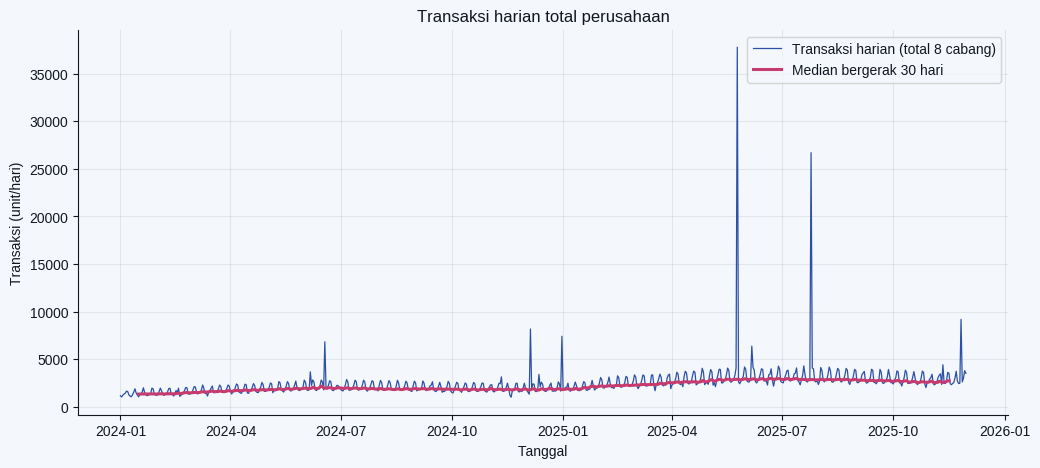

In [31]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(tw.index, tw.values, lw=0.9, color='#2C50A5', label='Transaksi harian (total 8 cabang)')
ax.plot(tw.index, tw.rolling(30, center=True).median().values, lw=2.2, color='#C73B6F',
        label='Median bergerak 30 hari')
ax.set_title('Transaksi harian total perusahaan')
ax.set_xlabel('Tanggal'); ax.set_ylabel('Transaksi (unit/hari)')
ax.legend()
plt.show()

Profil musiman (deviasi dari tren, transaksi/hari):
  Senin  :   -463.3
  Selasa :   -418.5
  Rabu   :   -400.8
  Kamis  :   -247.9
  Jumat  :   +283.8
  Sabtu  :   +551.0
  Minggu :   +712.8
Amplitudo musiman (puncak - lembah): 1176.1 transaksi/hari
Tren: slope +20.24 transaksi/hari per pekan (linregress pada komponen tren, p=1.1e-84)
Rata-rata 30 hari pertama vs terakhir: 1393 -> 3132 (+124.9%)
Std residual: 1530.2 vs std deret: 1827.7


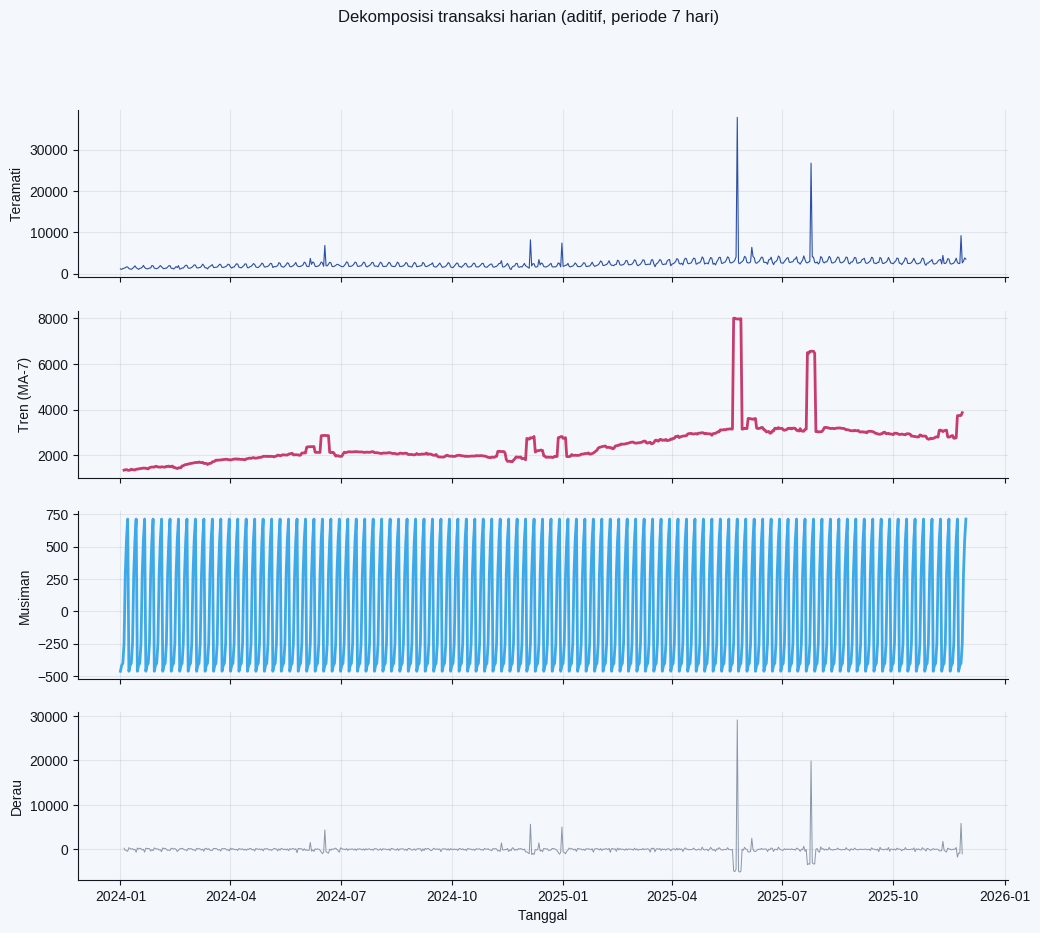

In [32]:
nama_hari = ['Senin', 'Selasa', 'Rabu', 'Kamis', 'Jumat', 'Sabtu', 'Minggu']
y = tw
trend = y.rolling(7, center=True).mean()
profil = (y - trend).groupby(y.index.dayofweek).mean()         
seasonal = y.index.dayofweek.map(profil)
resid = y - trend - seasonal

print('Profil musiman (deviasi dari tren, transaksi/hari):')
for d in range(7):
    print(f'  {nama_hari[d]:<7}: {profil[d]:+8.1f}')
amp = profil.max() - profil.min()
print(f'Amplitudo musiman (puncak - lembah): {amp:.1f} transaksi/hari')

slope, icept, r, p, se = stats.linregress(np.arange(len(trend.dropna())) / 7, trend.dropna())
print(f'Tren: slope {slope:+.2f} transaksi/hari per pekan (linregress pada komponen tren, p={p:.1e})')
print(f'Rata-rata 30 hari pertama vs terakhir: {y.iloc[:30].mean():.0f} -> {y.iloc[-30:].mean():.0f} '
      f'({(y.iloc[-30:].mean()/y.iloc[:30].mean()-1)*100:+.1f}%)')
print(f'Std residual: {resid.std():.1f} vs std deret: {y.std():.1f}')

fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
axes[0].plot(y.index, y.values, lw=0.8, color='#2C50A5'); axes[0].set_ylabel('Teramati')
axes[1].plot(trend.index, trend.values, color='#C73B6F'); axes[1].set_ylabel('Tren (MA-7)')
axes[2].plot(y.index, seasonal, color='#3EA9E8'); axes[2].set_ylabel('Musiman')
axes[3].plot(resid.index, resid.values, lw=0.7, color='#8A96A8'); axes[3].set_ylabel('Derau')
axes[3].set_xlabel('Tanggal')
fig.suptitle('Dekomposisi transaksi harian (aditif, periode 7 hari)')
plt.show()

In [33]:
rows = {}
for br in df_bersih.columns:
    sb = df_bersih[br].dropna().loc[:WINDOW_END]
    if len(sb) < 60:
        continue
    tb = sb.rolling(7, center=True).mean()
    prof_b = (sb - tb).groupby(sb.index.dayofweek).mean()
    sl_b, _, _, p_b, _ = stats.linregress(np.arange(len(tb.dropna())) / 7, tb.dropna())
    rows[br] = {'weekly_amplitude': round(prof_b.max() - prof_b.min(), 1),
                'slope (weekly)': round(sl_b, 2),
                'p_slope': f'{p_b:.2f}',
                'median': round(sb.median(), 0)}
print(pd.DataFrame(rows))


                 Bandung Bekasi Cimahi Cirebon  Depok  Garut Sumedang  \
weekly_amplitude   220.3  494.3  182.0   111.2  157.6   80.7     73.5   
slope (weekly)      2.74   5.01   6.69    1.15   2.07   0.74     1.19   
p_slope             0.00   0.00   0.00    0.00   0.00   0.00     0.00   
median             461.0  377.0  309.0   249.0  349.0  162.0    132.0   

                 Tasikmalaya  
weekly_amplitude        94.9  
slope (weekly)          1.23  
p_slope                 0.00  
median                 198.0  


#### B2

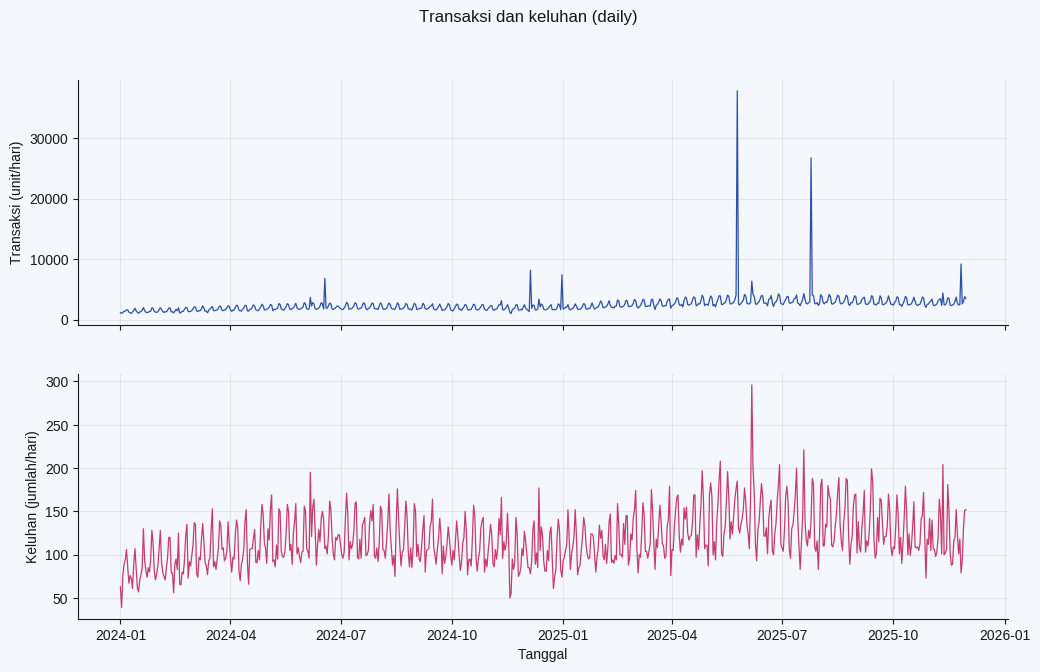

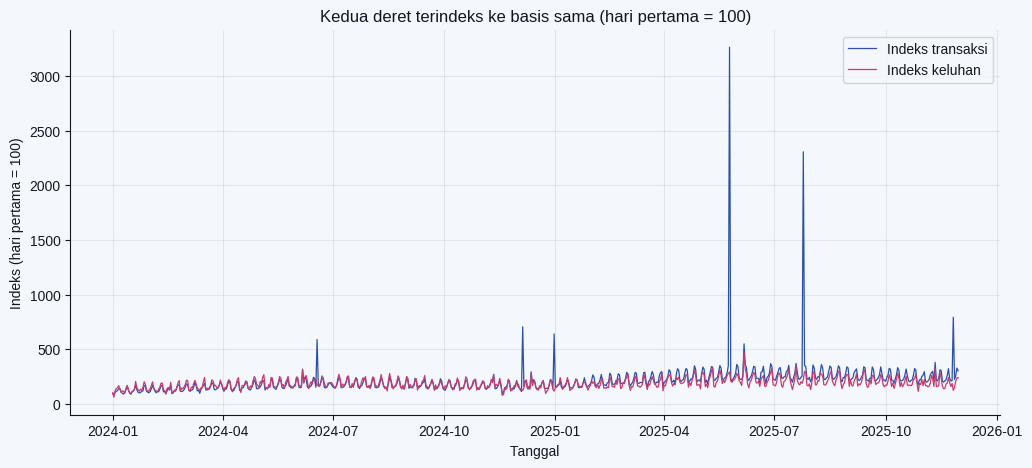

In [34]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(tw.index, tw.values, lw=0.9, color='#2C50A5')
axes[0].set_ylabel('Transaksi (unit/hari)')
axes[1].plot(twk.index, twk.values, lw=0.9, color='#C73B6F')
axes[1].set_ylabel('Keluhan (jumlah/hari)'); axes[1].set_xlabel('Tanggal')
fig.suptitle('Transaksi dan keluhan (daily)')
plt.show()

idx_t = tw / tw.iloc[0] * 100
idx_k = twk / twk.iloc[0] * 100
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(idx_t.index, idx_t.values, lw=0.9, color='#2C50A5', label='Indeks transaksi')
ax.plot(idx_k.index, idx_k.values, lw=0.9, color='#C73B6F', label='Indeks keluhan')
ax.set_title('Kedua deret terindeks ke basis sama (hari pertama = 100)')
ax.set_xlabel('Tanggal'); ax.set_ylabel('Indeks (hari pertama = 100)'); ax.legend()
plt.show()

In [35]:
r1 = stats.pearsonr(twk, tw); s1 = stats.spearmanr(twk, tw)
print(f'Korelasi : Pearson = {r1[0]:.3f} & Spearman = {s1[0]:.3f}')

Korelasi : Pearson = 0.394 & Spearman = 0.807


Corr Ratio (keluhan/transaksi vs transaksi): Pearson = -0.515 & Spearman = -0.602
Rata-rata rasio: 0.052 keluhan per transaksi (median 0.051)


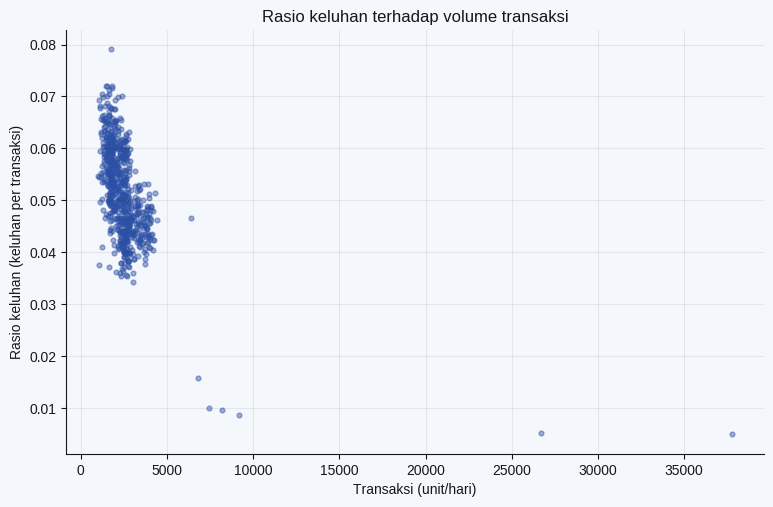

In [36]:
rate = (twk / tw).replace([np.inf, -np.inf], np.nan).dropna()
y_al = tw.loc[rate.index]
r3 = stats.pearsonr(rate, y_al); s3 = stats.spearmanr(rate, y_al)
print(f'Corr Ratio (keluhan/transaksi vs transaksi): Pearson = {r3[0]:.3f} '
      f'& Spearman = {s3[0]:.3f}')
print(f'Rata-rata rasio: {rate.mean():.3f} keluhan per transaksi (median {rate.median():.3f})')

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(y_al.values, rate.values, s=12, alpha=0.45, color='#2C50A5')
ax.set_xlabel('Transaksi (unit/hari)'); ax.set_ylabel('Rasio keluhan (keluhan per transaksi)')
ax.set_title('Rasio keluhan terhadap volume transaksi')
plt.show()